# AWS basics track: accounts, IAM, VPC and inbound / outbound traffic

Every other track assumes these foundations. You build the network and access set-up a bank's lending platform would sit on:

| Part | Topic | You will learn |
|---|---|---|
| 1 | Account, region, ARN | Who you are and how AWS names things |
| 2 | IAM | Users, groups, policies, roles, allow vs deny |
| 3 | VPC | CIDR ranges, public and private subnets, gateways, routing |
| 4 | Inbound and outbound | Security groups (stateful) vs network ACLs (stateless) |
| 5 | Compute | Launching an instance into your network |
| 6 | Data protection | Blocking public access, TLS-only and encryption |

Everything runs against AWS Emulator, so you can break things freely. Start the emulator first (repository README, step 1).

In [1]:
import sys, json, time, ipaddress
sys.path.insert(0, "../..")          # repository root: emu.py, lab_common.py
import boto3
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch
from botocore.exceptions import ClientError
import emu
from lab_common import attempt
from netcheck import check_inbound

for _ in range(30):                  # the emulator takes a few seconds to start
    if emu.health():
        break
    time.sleep(1)
assert emu.health(), "Emulator is not reachable. Start it, then re-run this cell."
ec2, iam, sts, s3 = (emu.client(n) for n in ("ec2", "iam", "sts", "s3"))
ACCOUNT = sts.get_caller_identity()["Account"]
print("Connected to", emu.settings()["endpoint_url"])

Connected to https://127.0.0.1:9297


## 1. Account, region and ARNs

- An **account** is the boundary for billing and security. The emulator uses `000000000000`.
- A **region** (`us-east-1`) is a geographic area; it contains several **availability zones** (separate data centres). Spreading across zones protects you from one site failing.
- An **ARN** (Amazon Resource Name) identifies any resource: `arn:partition:service:region:account:resource`.

`GetCallerIdentity` answers "who am I signed in as?". Run it first whenever access behaves unexpectedly.

In [2]:
me = sts.get_caller_identity()
print("Account :", me["Account"])
print("Identity:", me["Arn"])
zones = [z["ZoneName"] for z in ec2.describe_availability_zones()["AvailabilityZones"]]
print("Zones   :", zones)

arn = "arn:aws:s3:::bank-secure-docs/loans/summary.csv"
pd.DataFrame([dict(zip(["arn", "partition", "service", "region", "account", "resource"], arn.split(":", 5)))])

Account : 000000000000
Identity: arn:aws:iam::000000000000:user/emulator
Zones   : ['us-east-1a', 'us-east-1b', 'us-east-1c']


,arn,partition,service,region,account,resource
0,arn,aws,s3,,,bank-secure-docs/loans/summary.csv


## 2. IAM: who can do what

IAM decides every request with three rules:

1. **Everything is denied by default** (an *implicit deny*).
2. An **Allow** in a policy grants access.
3. An explicit **Deny** always wins, whatever else allows.

Good practice: give people permissions through **groups**, grant the **least privilege** needed, and use **roles** for temporary, elevated access.

### 2.1 A user, a group and a read-only policy

In [3]:
LAKE = "bank-secure-docs"            # this lab's own bucket, so the other labs are unaffected
if LAKE not in [b["Name"] for b in s3.list_buckets()["Buckets"]]:
    s3.create_bucket(Bucket=LAKE)
for reset in (s3.delete_bucket_encryption, s3.delete_bucket_policy):   # undo part 6 from a previous run
    attempt(reset.__name__, lambda: reset(Bucket=LAKE))
s3.put_object(Bucket=LAKE, Key="loans/summary.csv", Body=b"segment,loans\nSalaried,1013\n")
s3.put_object(Bucket=LAKE, Key="pii/customers.csv", Body=b"customer_id,name\nC1,(synthetic)\n")

def ensure(label, fn):
    """Create something unless it already exists, so this notebook can be re-run."""
    try:
        return fn()
    except ClientError as e:
        if e.response["Error"]["Code"] not in ("EntityAlreadyExists", "EntityAlreadyExistsException"):
            raise

read_lake = {"Version": "2012-10-17", "Statement": [{
    "Sid": "ReadTheLake", "Effect": "Allow",
    "Action": ["s3:ListBucket", "s3:GetObject"],
    "Resource": [f"arn:aws:s3:::{LAKE}", f"arn:aws:s3:::{LAKE}/*"]}]}

ensure("user", lambda: iam.create_user(UserName="analyst"))
ensure("group", lambda: iam.create_group(GroupName="analysts"))
iam.add_user_to_group(GroupName="analysts", UserName="analyst")
policy_arn = f"arn:aws:iam::{ACCOUNT}:policy/ReadLake"
if not ensure("policy", lambda: iam.create_policy(PolicyName="ReadLake", PolicyDocument=json.dumps(read_lake))):
    # It exists from an earlier run: save this document as the new default version (AWS keeps at most five).
    for v in iam.list_policy_versions(PolicyArn=policy_arn)["Versions"]:
        if not v["IsDefaultVersion"]:
            iam.delete_policy_version(PolicyArn=policy_arn, VersionId=v["VersionId"])
    iam.create_policy_version(PolicyArn=policy_arn, PolicyDocument=json.dumps(read_lake), SetAsDefault=True)
iam.attach_group_policy(GroupName="analysts", PolicyArn=policy_arn)
print(json.dumps(read_lake, indent=2))

OK      delete_bucket_encryption
OK      delete_bucket_policy
{
  "Version": "2012-10-17",
  "Statement": [
    {
      "Sid": "ReadTheLake",
      "Effect": "Allow",
      "Action": [
        "s3:ListBucket",
        "s3:GetObject"
      ],
      "Resource": [
        "arn:aws:s3:::bank-secure-docs",
        "arn:aws:s3:::bank-secure-docs/*"
      ]
    }
  ]
}


### 2.2 Ask IAM before you try

The policy simulator evaluates a request without making it. Useful for reviewing access.

In [4]:
results = iam.simulate_principal_policy(
    PolicySourceArn=f"arn:aws:iam::{ACCOUNT}:user/analyst",
    ActionNames=["s3:GetObject", "s3:PutObject", "s3:DeleteObject", "ec2:DescribeVpcs"],
    ResourceArns=[f"arn:aws:s3:::{LAKE}/loans/summary.csv"])["EvaluationResults"]
pd.DataFrame([{"action": r["EvalActionName"], "decision": r["EvalDecision"]} for r in results])

,action,decision
0,s3:GetObject,allowed
1,s3:PutObject,implicitDeny
2,s3:DeleteObject,implicitDeny
3,ec2:DescribeVpcs,implicitDeny


### 2.3 Sign in as the analyst and test for real

Create an access key for the analyst and make calls with it. The emulator enforces IAM, so the refusals below are genuine decisions, with the same messages AWS gives.

In [5]:
for k in iam.list_access_keys(UserName="analyst")["AccessKeyMetadata"]:   # one fresh key per run
    iam.delete_access_key(UserName="analyst", AccessKeyId=k["AccessKeyId"])
key = iam.create_access_key(UserName="analyst")["AccessKey"]

def client_as(service, creds):
    s = emu.settings()
    return boto3.client(service, endpoint_url=s["endpoint_url"], verify=s["verify"], region_name="us-east-1",
                        aws_access_key_id=creds["AccessKeyId"], aws_secret_access_key=creds["SecretAccessKey"],
                        aws_session_token=creds.get("SessionToken"))

time.sleep(1)
analyst_s3, analyst_sts = client_as("s3", key), client_as("sts", key)
print("Signed in as:", analyst_sts.get_caller_identity()["Arn"], "\n")
attempt("read loans/summary.csv", lambda: analyst_s3.get_object(Bucket=LAKE, Key="loans/summary.csv"))
attempt("delete loans/summary.csv", lambda: analyst_s3.delete_object(Bucket=LAKE, Key="loans/summary.csv"))
attempt("create a new bucket", lambda: analyst_s3.create_bucket(Bucket="analyst-sandbox"))
attempt("list VPCs", lambda: client_as("ec2", key).describe_vpcs())

Signed in as: arn:aws:iam::000000000000:user/analyst 

OK      read loans/summary.csv
REFUSED delete loans/summary.csv: AccessDenied - User: arn:aws:iam::000000000000:user/analyst is not authorized to perform: s3:DeleteObject on resource: "arn:aws:s3:::bank-secure-docs/loans/summary.csv" because no identity-based policy allows the s3
REFUSED create a new bucket: AccessDenied - User: arn:aws:iam::000000000000:user/analyst is not authorized to perform: s3:CreateBucket on resource: "arn:aws:s3:::analyst-sandbox" because no identity-based policy allows the s3:CreateBucket actio
REFUSED list VPCs: UnauthorizedOperation - You are not authorized to perform this operation. User: arn:aws:iam::000000000000:user/analyst is not authorized to perform: ec2:DescribeVpcs because no identity-based policy allows the ec2:DescribeVp


### 2.4 An explicit Deny wins

The group can read the whole bucket, but personal data under `pii/` must stay off-limits. One Deny statement does it, even though the Allow still matches.

In [6]:
iam.put_group_policy(GroupName="analysts", PolicyName="DenyPII", PolicyDocument=json.dumps({
    "Version": "2012-10-17", "Statement": [{"Effect": "Deny", "Action": "s3:GetObject",
                                             "Resource": f"arn:aws:s3:::{LAKE}/pii/*"}]}))
time.sleep(1)
attempt("read loans/summary.csv", lambda: analyst_s3.get_object(Bucket=LAKE, Key="loans/summary.csv"))
attempt("read pii/customers.csv", lambda: analyst_s3.get_object(Bucket=LAKE, Key="pii/customers.csv"))

OK      read loans/summary.csv
REFUSED read pii/customers.csv: AccessDenied - User: arn:aws:iam::000000000000:user/analyst is not authorized to perform: s3:GetObject on resource: "arn:aws:s3:::bank-secure-docs/pii/customers.csv" with an explicit deny in an identity-based policy


### 2.5 Roles: temporary, elevated access

A **role** has no password or long-term key. Someone *assumes* it and receives short-lived credentials. Two policies are involved:

- the **trust policy** says *who* may assume the role;
- the **permissions policy** says *what* the role may do.

Here a `lake-admin` role may delete objects, and only the analyst may assume it.

In [7]:
trust = {"Version": "2012-10-17", "Statement": [{"Effect": "Allow", "Action": "sts:AssumeRole",
         "Principal": {"AWS": f"arn:aws:iam::{ACCOUNT}:user/analyst"}}]}
ensure("role", lambda: iam.create_role(RoleName="lake-admin", AssumeRolePolicyDocument=json.dumps(trust),
                                       MaxSessionDuration=3600, Description="Break-glass access to the lake"))
iam.put_role_policy(RoleName="lake-admin", PolicyName="ManageLake", PolicyDocument=json.dumps({
    "Version": "2012-10-17", "Statement": [{"Effect": "Allow", "Action": "s3:*",
    "Resource": [f"arn:aws:s3:::{LAKE}", f"arn:aws:s3:::{LAKE}/*"]}]}))
time.sleep(1)

session = analyst_sts.assume_role(RoleArn=f"arn:aws:iam::{ACCOUNT}:role/lake-admin", RoleSessionName="ticket-4711",
                                  DurationSeconds=900)["Credentials"]
print("Now acting as:", client_as("sts", session).get_caller_identity()["Arn"])
print("Credentials expire at:", session["Expiration"], "\n")
s3.put_object(Bucket=LAKE, Key="tmp/old-extract.csv", Body=b"x")
attempt("delete tmp/old-extract.csv as lake-admin", lambda: client_as("s3", session).delete_object(Bucket=LAKE, Key="tmp/old-extract.csv"))

# Someone the trust policy does not name is refused.
ensure("user", lambda: iam.create_user(UserName="intern"))
for k in iam.list_access_keys(UserName="intern")["AccessKeyMetadata"]:
    iam.delete_access_key(UserName="intern", AccessKeyId=k["AccessKeyId"])
intern_key = iam.create_access_key(UserName="intern")["AccessKey"]
time.sleep(1)
attempt("intern assumes lake-admin", lambda: client_as("sts", intern_key).assume_role(
    RoleArn=f"arn:aws:iam::{ACCOUNT}:role/lake-admin", RoleSessionName="try"))

Now acting as: arn:aws:sts::000000000000:assumed-role/lake-admin/ticket-4711
Credentials expire at: 2026-11-18 05:51:21+00:00 

OK      delete tmp/old-extract.csv as lake-admin


REFUSED intern assumes lake-admin: AccessDenied - User: arn:aws:iam::000000000000:user/intern is not authorized to perform: sts:AssumeRole on resource: arn:aws:iam::000000000000:role/lake-admin


> **Emulator gap.** In real AWS, when a trust policy names the whole account (`arn:aws:iam::ACCOUNT:root`) rather than a specific user, the user *also* needs an identity policy allowing `sts:AssumeRole` on that role. The emulator currently skips that second check, so test that case on real AWS.

### 2.6 Account-wide guard rails

In [8]:
iam.update_account_password_policy(MinimumPasswordLength=14, RequireSymbols=True, RequireNumbers=True,
                                   RequireUppercaseCharacters=True, RequireLowercaseCharacters=True,
                                   MaxPasswordAge=90, PasswordReusePrevention=12)
summary = iam.get_account_summary()["SummaryMap"]
pd.DataFrame([{k: summary[k] for k in ("Users", "Groups", "Roles", "Policies")}])

,Users,Groups,Roles,Policies
0,5,2,3,2


## 3. VPC: your private network

A **VPC** is an isolated network with an address range written in CIDR notation. `10.0.0.0/16` means the first 16 bits are fixed, leaving 65,536 addresses.

Inside it you carve **subnets**, each in one availability zone:

- a **public subnet** has a route to an **internet gateway**, so things in it can be reached from the internet (for example a load balancer);
- a **private subnet** has no such route. It reaches out through a **NAT gateway**, which allows outbound connections but never accepts inbound ones. Databases and model servers belong here.

| Subnet | CIDR | Zone | Purpose |
|---|---|---|---|
| public-a | 10.0.1.0/24 | us-east-1a | Web / load balancer tier |
| public-b | 10.0.2.0/24 | us-east-1b | Second zone for resilience |
| private-a | 10.0.11.0/24 | us-east-1a | Application and database tier |
| private-b | 10.0.12.0/24 | us-east-1b | Second zone for resilience |

### 3.1 Start clean

This cell removes the VPC from a previous run, in the order AWS requires: you cannot delete a network while anything still uses it.

In [9]:
def tag(name):
    return [{"Key": "Name", "Value": name}, {"Key": "Project", "Value": "aws-basics"}]

def teardown(vpc_name="bank-vpc"):
    for vpc in ec2.describe_vpcs(Filters=[{"Name": "tag:Name", "Values": [vpc_name]}])["Vpcs"]:
        v, by_vpc = vpc["VpcId"], [{"Name": "vpc-id", "Values": [vpc["VpcId"]]}]
        ids = [i["InstanceId"] for r in ec2.describe_instances(Filters=by_vpc)["Reservations"] for i in r["Instances"]
               if i["State"]["Name"] != "terminated"]
        if ids:
            ec2.terminate_instances(InstanceIds=ids)
            ec2.get_waiter("instance_terminated").wait(InstanceIds=ids, WaiterConfig={"Delay": 1, "MaxAttempts": 60})
        for e in ec2.describe_vpc_endpoints(Filters=by_vpc)["VpcEndpoints"]:
            ec2.delete_vpc_endpoints(VpcEndpointIds=[e["VpcEndpointId"]])
        nats = [n["NatGatewayId"] for n in ec2.describe_nat_gateways(Filters=by_vpc)["NatGateways"] if n["State"] != "deleted"]
        for n in nats:
            ec2.delete_nat_gateway(NatGatewayId=n)
        if nats:
            ec2.get_waiter("nat_gateway_deleted").wait(NatGatewayIds=nats, WaiterConfig={"Delay": 1, "MaxAttempts": 60})
        for a in ec2.describe_addresses(Filters=[{"Name": "tag:Project", "Values": ["aws-basics"]}])["Addresses"]:
            if "AssociationId" not in a:          # still held by another VPC's NAT gateway otherwise
                ec2.release_address(AllocationId=a["AllocationId"])
        for g in ec2.describe_internet_gateways(Filters=[{"Name": "attachment.vpc-id", "Values": [v]}])["InternetGateways"]:
            ec2.detach_internet_gateway(InternetGatewayId=g["InternetGatewayId"], VpcId=v)
            ec2.delete_internet_gateway(InternetGatewayId=g["InternetGatewayId"])
        for sn in ec2.describe_subnets(Filters=by_vpc)["Subnets"]:
            ec2.delete_subnet(SubnetId=sn["SubnetId"])
        for rt in ec2.describe_route_tables(Filters=by_vpc)["RouteTables"]:
            if not any(a.get("Main") for a in rt["Associations"]):
                ec2.delete_route_table(RouteTableId=rt["RouteTableId"])
        groups = [g for g in ec2.describe_security_groups(Filters=by_vpc)["SecurityGroups"] if g["GroupName"] != "default"]
        for g in groups:                       # remove cross-references before deleting
            if g["IpPermissions"]:
                ec2.revoke_security_group_ingress(GroupId=g["GroupId"], IpPermissions=g["IpPermissions"])
        for g in groups:
            ec2.delete_security_group(GroupId=g["GroupId"])
        for acl in ec2.describe_network_acls(Filters=by_vpc)["NetworkAcls"]:
            if not acl["IsDefault"]:
                ec2.delete_network_acl(NetworkAclId=acl["NetworkAclId"])
        ec2.delete_vpc(VpcId=v)
        print("Removed previous", vpc_name, v)

teardown()

Removed previous bank-vpc vpc-000000000000001d1


### 3.2 Create the VPC and subnets

The last two calls are deliberate mistakes: AWS refuses a subnet that overlaps another, or lies outside the VPC's range.

In [10]:
vpc = ec2.create_vpc(CidrBlock="10.0.0.0/16", TagSpecifications=[{"ResourceType": "vpc", "Tags": tag("bank-vpc")}])["Vpc"]["VpcId"]
ec2.modify_vpc_attribute(VpcId=vpc, EnableDnsHostnames={"Value": True})

PLAN = [("public-a", "10.0.1.0/24", "us-east-1a"), ("public-b", "10.0.2.0/24", "us-east-1b"),
        ("private-a", "10.0.11.0/24", "us-east-1a"), ("private-b", "10.0.12.0/24", "us-east-1b")]
subnets = {name: ec2.create_subnet(VpcId=vpc, CidrBlock=cidr, AvailabilityZone=az,
                                   TagSpecifications=[{"ResourceType": "subnet", "Tags": tag(name)}])["Subnet"]["SubnetId"]
           for name, cidr, az in PLAN}
for name in ("public-a", "public-b"):
    ec2.modify_subnet_attribute(SubnetId=subnets[name], MapPublicIpOnLaunch={"Value": True})

attempt("subnet overlapping public-a", lambda: ec2.create_subnet(VpcId=vpc, CidrBlock="10.0.1.128/25"))
attempt("subnet outside the VPC", lambda: ec2.create_subnet(VpcId=vpc, CidrBlock="192.168.0.0/24"))

info = ec2.describe_subnets(SubnetIds=list(subnets.values()))["Subnets"]
name_of = {v: k for k, v in subnets.items()}
pd.DataFrame([{"subnet": name_of[s["SubnetId"]], "cidr": s["CidrBlock"], "zone": s["AvailabilityZone"],
               "usable addresses": s["AvailableIpAddressCount"], "public IP on launch": s["MapPublicIpOnLaunch"]}
              for s in info]).sort_values("subnet")

REFUSED subnet overlapping public-a: InvalidSubnet.Conflict - The CIDR '10.0.1.128/25' conflicts with another subnet
REFUSED subnet outside the VPC: InvalidSubnet.Range - The CIDR '192.168.0.0/24' is invalid.


,subnet,cidr,zone,usable addresses,public IP on launch
2,private-a,10.0.11.0/24,us-east-1a,251,False
3,private-b,10.0.12.0/24,us-east-1b,251,False
0,public-a,10.0.1.0/24,us-east-1a,251,True
1,public-b,10.0.2.0/24,us-east-1b,251,True


A `/24` has 256 addresses but only **251** are usable: AWS reserves five in every subnet (network address, router, DNS, one for future use, broadcast).

In [11]:
net = ipaddress.ip_network("10.0.1.0/24")
reserved = [net[0], net[1], net[2], net[3], net[-1]]
print("Total:", net.num_addresses, " Reserved by AWS:", [str(a) for a in reserved], " Usable:", net.num_addresses - 5)

Total: 256  Reserved by AWS: ['10.0.1.0', '10.0.1.1', '10.0.1.2', '10.0.1.3', '10.0.1.255']  Usable: 251


### 3.3 Gateways and route tables

A **route table** says where traffic goes. Every table has a `local` route, so anything inside the VPC can reach anything else in it. We add:

- **public route table:** `0.0.0.0/0` (everything else) → internet gateway;
- **private route table:** `0.0.0.0/0` → NAT gateway, plus a free **gateway endpoint** so S3 traffic stays on AWS's network instead of going through the NAT.

In [12]:
igw = ec2.create_internet_gateway(TagSpecifications=[{"ResourceType": "internet-gateway", "Tags": tag("bank-igw")}])["InternetGateway"]["InternetGatewayId"]
ec2.attach_internet_gateway(InternetGatewayId=igw, VpcId=vpc)

public_rt = ec2.create_route_table(VpcId=vpc, TagSpecifications=[{"ResourceType": "route-table", "Tags": tag("public-rt")}])["RouteTable"]["RouteTableId"]
ec2.create_route(RouteTableId=public_rt, DestinationCidrBlock="0.0.0.0/0", GatewayId=igw)

eip = ec2.allocate_address(Domain="vpc", TagSpecifications=[{"ResourceType": "elastic-ip", "Tags": tag("nat-eip")}])
nat = ec2.create_nat_gateway(SubnetId=subnets["public-a"], AllocationId=eip["AllocationId"],
                             TagSpecifications=[{"ResourceType": "natgateway", "Tags": tag("bank-nat")}])["NatGateway"]["NatGatewayId"]
ec2.get_waiter("nat_gateway_available").wait(NatGatewayIds=[nat], WaiterConfig={"Delay": 1, "MaxAttempts": 30})

private_rt = ec2.create_route_table(VpcId=vpc, TagSpecifications=[{"ResourceType": "route-table", "Tags": tag("private-rt")}])["RouteTable"]["RouteTableId"]
ec2.create_route(RouteTableId=private_rt, DestinationCidrBlock="0.0.0.0/0", NatGatewayId=nat)
ec2.create_vpc_endpoint(VpcId=vpc, ServiceName="com.amazonaws.us-east-1.s3", VpcEndpointType="Gateway", RouteTableIds=[private_rt])

for name in subnets:
    ec2.associate_route_table(RouteTableId=public_rt if name.startswith("public") else private_rt, SubnetId=subnets[name])

rows = []
for label, rt in (("public-rt", public_rt), ("private-rt", private_rt)):
    for r in ec2.describe_route_tables(RouteTableIds=[rt])["RouteTables"][0]["Routes"]:
        rows.append({"route table": label, "destination": r.get("DestinationCidrBlock") or f'{r.get("DestinationPrefixListId")} (S3)',
                     "target": r.get("GatewayId") or r.get("NatGatewayId"), "state": r.get("State")})
pd.DataFrame(rows)

,route table,destination,target,state
0,public-rt,10.0.0.0/16,local,active
1,public-rt,0.0.0.0/0,igw-00000000000000211,active
2,private-rt,10.0.0.0/16,local,active
3,private-rt,0.0.0.0/0,nat-00000000000000215,active
4,private-rt,pl-e9da6b72 (S3),vpce-00000000000000218,active


### 3.4 Picture of what you built

Drawn from what the emulator now holds.

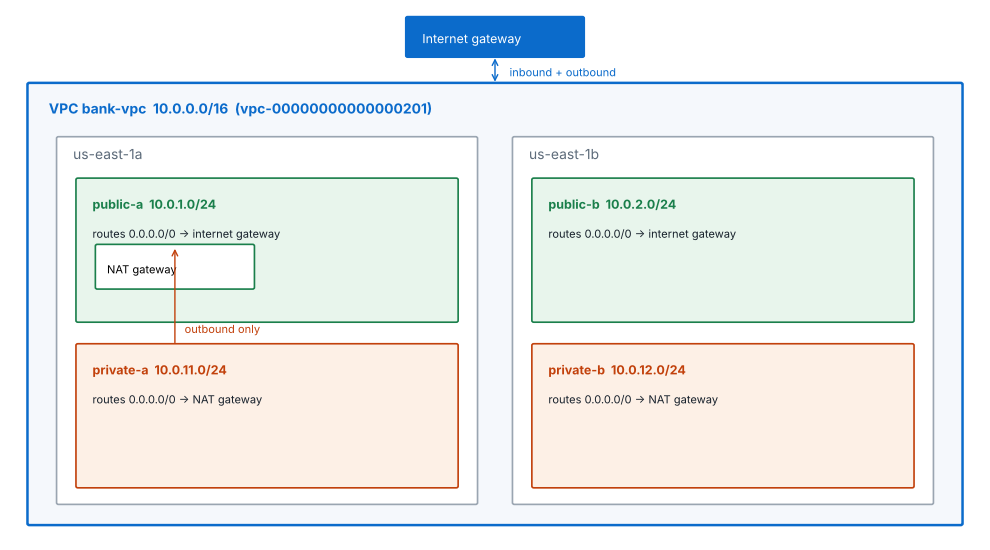

In [13]:
fig, ax = plt.subplots(figsize=(10, 5.6)); ax.set_xlim(0, 10); ax.set_ylim(0, 6.4); ax.axis("off")
box = lambda x, y, w, h, fc, ec, lw=1.2: ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.02", fc=fc, ec=ec, lw=lw))
box(0.2, 0.2, 9.6, 5.3, "#f5f8fc", "#0b6bcb", 1.8); ax.text(0.4, 5.15, f"VPC bank-vpc  10.0.0.0/16  ({vpc})", color="#0b6bcb", weight="bold")
for col, az in enumerate(("us-east-1a", "us-east-1b")):
    x = 0.5 + col * 4.7
    box(x, 0.45, 4.3, 4.4, "white", "#9aa5b1"); ax.text(x + 0.15, 4.6, az, color="#5d6b7a")
    for row, kind, fc, ec in ((1, "public", "#e8f5ec", "#1a7f4b"), (0, "private", "#fdf0e6", "#c2410c")):
        name = f"{kind}-{az[-1]}"; y = 0.65 + row * 2.0
        box(x + 0.2, y, 3.9, 1.7, fc, ec); ax.text(x + 0.35, y + 1.35, f"{name}  {dict((n, c) for n, c, _ in PLAN)[name]}", color=ec, weight="bold", fontsize=9)
        ax.text(x + 0.35, y + 1.0, f"routes 0.0.0.0/0 → {'internet gateway' if kind == 'public' else 'NAT gateway'}", fontsize=8, color="#16202b")
box(0.9, 3.05, 1.6, 0.5, "#fff", "#1a7f4b"); ax.text(1.0, 3.22, "NAT gateway", fontsize=8)
box(4.1, 5.85, 1.8, 0.45, "#0b6bcb", "#0b6bcb"); ax.text(4.25, 6.0, "Internet gateway", color="white", fontsize=9)
ax.annotate("", xy=(5.0, 5.5), xytext=(5.0, 5.85), arrowprops=dict(arrowstyle="<->", color="#0b6bcb"))
ax.text(5.15, 5.6, "inbound + outbound", fontsize=8, color="#0b6bcb")
ax.annotate("", xy=(1.7, 3.55), xytext=(1.7, 2.35), arrowprops=dict(arrowstyle="->", color="#c2410c"))
ax.text(1.8, 2.5, "outbound only", fontsize=8, color="#c2410c")
plt.tight_layout(); plt.show()

## 4. Inbound and outbound traffic

Two layers filter traffic. Both have **inbound** (ingress) and **outbound** (egress) rules.

| | Security group | Network ACL |
|---|---|---|
| Attached to | An instance's network interface | A whole subnet |
| Rule types | Allow only | Allow and deny |
| Evaluation | All rules together | In rule-number order; first match wins |
| State | **Stateful**: a reply to allowed traffic is allowed automatically | **Stateless**: the reply is checked again, in the other direction |
| Default (new) | No inbound, all outbound | Custom ACL: deny everything |

### 4.1 Security groups for a three-tier app

- `web-sg`: HTTPS (443) from anywhere;
- `app-sg`: port 8080 only from `web-sg` (a reference to another group, not an IP range);
- `db-sg`: PostgreSQL (5432) only from `app-sg`, and **no outbound at all**.

In [14]:
def make_sg(name, description):
    return ec2.create_security_group(GroupName=name, Description=description, VpcId=vpc,
                                     TagSpecifications=[{"ResourceType": "security-group", "Tags": tag(name)}])["GroupId"]

web_sg, app_sg, db_sg = make_sg("web-sg", "Public HTTPS"), make_sg("app-sg", "Scoring service"), make_sg("db-sg", "Loan database")
print("New group's default outbound rule:", ec2.describe_security_groups(GroupIds=[db_sg])["SecurityGroups"][0]["IpPermissionsEgress"])

ec2.authorize_security_group_ingress(GroupId=web_sg, IpPermissions=[{"IpProtocol": "tcp", "FromPort": 443, "ToPort": 443,
    "IpRanges": [{"CidrIp": "0.0.0.0/0", "Description": "HTTPS from the internet"}]}])
ec2.authorize_security_group_ingress(GroupId=app_sg, IpPermissions=[{"IpProtocol": "tcp", "FromPort": 8080, "ToPort": 8080,
    "UserIdGroupPairs": [{"GroupId": web_sg, "Description": "Only the web tier"}]}])
ec2.authorize_security_group_ingress(GroupId=db_sg, IpPermissions=[{"IpProtocol": "tcp", "FromPort": 5432, "ToPort": 5432,
    "UserIdGroupPairs": [{"GroupId": app_sg, "Description": "Only the scoring service"}]}])
ec2.revoke_security_group_egress(GroupId=db_sg, IpPermissions=[{"IpProtocol": "-1", "IpRanges": [{"CidrIp": "0.0.0.0/0"}]}])

attempt("add the same HTTPS rule twice", lambda: ec2.authorize_security_group_ingress(GroupId=web_sg, IpPermissions=[
    {"IpProtocol": "tcp", "FromPort": 443, "ToPort": 443, "IpRanges": [{"CidrIp": "0.0.0.0/0"}]}]))
attempt("delete web-sg while app-sg refers to it", lambda: ec2.delete_security_group(GroupId=web_sg))

names = {web_sg: "web-sg", app_sg: "app-sg", db_sg: "db-sg"}
rules = ec2.describe_security_group_rules(Filters=[{"Name": "group-id", "Values": list(names)}])["SecurityGroupRules"]
pd.DataFrame([{"group": names[r["GroupId"]], "direction": "outbound" if r["IsEgress"] else "inbound",
               "protocol": "all" if r["IpProtocol"] == "-1" else r["IpProtocol"],
               "port": "all" if r.get("FromPort", -1) == -1 else r["FromPort"],
               "peer": r.get("CidrIpv4") or names.get(r.get("ReferencedGroupInfo", {}).get("GroupId"), "?"),
               "description": r.get("Description", "")} for r in rules]).sort_values(["group", "direction"])

New group's default outbound rule: [{'IpProtocol': '-1', 'UserIdGroupPairs': [], 'IpRanges': [{'CidrIp': '0.0.0.0/0'}], 'Ipv6Ranges': [], 'PrefixListIds': []}]
REFUSED add the same HTTPS rule twice: InvalidPermission.Duplicate - the specified rule "peer: 0.0.0.0/0, TCP, from port: 443, to port: 443, ALLOW" already exists
REFUSED delete web-sg while app-sg refers to it: DependencyViolation - resource sg-0000000000000021d has a dependent object


,group,direction,protocol,port,peer,description
3,app-sg,inbound,tcp,8080,web-sg,Only the web tier
1,app-sg,outbound,all,all,0.0.0.0/0,
4,db-sg,inbound,tcp,5432,app-sg,Only the scoring service
2,web-sg,inbound,tcp,443,0.0.0.0/0,HTTPS from the internet
0,web-sg,outbound,all,all,0.0.0.0/0,


### 4.2 A network ACL for the public subnets

Because ACLs are stateless, allowing HTTPS **in** is not enough: the reply goes **out** to the client's *ephemeral port* (a random high port, 1024–65535), and that needs its own outbound rule.

Rule 90 denies a known-bad range before rule 100 can allow it. Security groups cannot express a deny like this.

In [15]:
acl = ec2.create_network_acl(VpcId=vpc, TagSpecifications=[{"ResourceType": "network-acl", "Tags": tag("public-acl")}])["NetworkAcl"]["NetworkAclId"]
entry = lambda n, out, action, cidr, ports=None, proto="6": ec2.create_network_acl_entry(
    NetworkAclId=acl, RuleNumber=n, Egress=out, RuleAction=action, Protocol=proto, CidrBlock=cidr,
    **({"PortRange": {"From": ports[0], "To": ports[1]}} if ports else {}))
entry(90,  False, "deny",  "203.0.113.0/24", proto="-1")   # blocked range (a documentation range, for the example)
entry(100, False, "allow", "0.0.0.0/0", (443, 443))       # HTTPS requests in
entry(100, True,  "allow", "0.0.0.0/0", (1024, 65535))    # replies out to ephemeral ports
entry(110, True,  "allow", "10.0.0.0/16", (8080, 8080))   # web tier to scoring service

default_acl = ec2.describe_network_acls(Filters=[{"Name": "vpc-id", "Values": [vpc]}, {"Name": "default", "Values": ["true"]}])["NetworkAcls"][0]
for a in default_acl["Associations"]:
    if a["SubnetId"] in (subnets["public-a"], subnets["public-b"]):
        ec2.replace_network_acl_association(AssociationId=a["NetworkAclAssociationId"], NetworkAclId=acl)

public_acl = ec2.describe_network_acls(NetworkAclIds=[acl])["NetworkAcls"][0]
pd.DataFrame([{"direction": "outbound" if e["Egress"] else "inbound", "rule": e["RuleNumber"] if e["RuleNumber"] != 32767 else "*",
               "action": e["RuleAction"], "protocol": {"6": "tcp", "-1": "all"}.get(e["Protocol"], e["Protocol"]),
               "ports": f'{e["PortRange"]["From"]}-{e["PortRange"]["To"]}' if e.get("PortRange") else "all", "cidr": e["CidrBlock"]}
              for e in sorted(public_acl["Entries"], key=lambda e: (e["Egress"], e["RuleNumber"]))])

,direction,rule,action,protocol,ports,cidr
0,inbound,90,deny,all,all,203.0.113.0/24
1,inbound,100,allow,tcp,443-443,0.0.0.0/0
2,inbound,*,deny,all,all,0.0.0.0/0
3,outbound,100,allow,tcp,1024-65535,0.0.0.0/0
4,outbound,110,allow,tcp,8080-8080,10.0.0.0/16
5,outbound,*,deny,all,all,0.0.0.0/0


### 4.3 Would this traffic get through?

The emulator stores these rules exactly as AWS does but does not move packets. `netcheck.py` (next to this notebook, worth reading) applies AWS's evaluation rules to the stored rules and explains each decision.

In [16]:
web = ec2.describe_security_groups(GroupIds=[web_sg])["SecurityGroups"][0]
scenarios = [
    check_inbound("Customer opens the website (HTTPS)", src_ip="198.51.100.7", src_port=51000, dst_port=443, protocol="tcp", target_sg=web, target_acl=public_acl),
    check_inbound("Someone tries SSH from the internet", src_ip="198.51.100.7", src_port=51001, dst_port=22, protocol="tcp", target_sg=web, target_acl=public_acl),
    check_inbound("HTTPS from the blocked range", src_ip="203.0.113.9", src_port=51002, dst_port=443, protocol="tcp", target_sg=web, target_acl=public_acl),
]
pd.DataFrame(scenarios)

,scenario,NACL inbound,security group,NACL outbound (reply),result
0,Customer opens the website (HTTPS),allow (rule 100),allow (tcp 443 from 0.0.0.0/0),allow (rule 100),Allowed
1,Someone tries SSH from the internet,deny (rule 32767),no matching rule,allow (rule 100),Blocked by NACL inbound rule 32767
2,HTTPS from the blocked range,deny (rule 90),allow (tcp 443 from 0.0.0.0/0),allow (rule 100),Blocked by NACL inbound rule 90


### 4.4 The stateless lesson

Delete the outbound ephemeral-port rule and check the website again. The request still arrives, but the reply can no longer leave, so customers see a timeout. This is one of the most common network mistakes.

In [17]:
ec2.delete_network_acl_entry(NetworkAclId=acl, RuleNumber=100, Egress=True)
broken = ec2.describe_network_acls(NetworkAclIds=[acl])["NetworkAcls"][0]
row = check_inbound("Website, without the outbound ephemeral rule", src_ip="198.51.100.7", src_port=51000, dst_port=443, protocol="tcp", target_sg=web, target_acl=broken)
entry(100, True, "allow", "0.0.0.0/0", (1024, 65535))     # put it back
fixed = ec2.describe_network_acls(NetworkAclIds=[acl])["NetworkAcls"][0]
pd.DataFrame([row, check_inbound("Website, rule restored", src_ip="198.51.100.7", src_port=51000, dst_port=443, protocol="tcp", target_sg=web, target_acl=fixed)])

,scenario,NACL inbound,security group,NACL outbound (reply),result
0,"Website, without the outbound ephemeral rule",allow (rule 100),allow (tcp 443 from 0.0.0.0/0),deny (rule 32767),"Request arrives, reply blocked by NACL outboun..."
1,"Website, rule restored",allow (rule 100),allow (tcp 443 from 0.0.0.0/0),allow (rule 100),Allowed


### 4.5 Between tiers: group references

Private subnets keep the default ACL (allow all), so the security groups do the work. Only an instance *in* `app-sg` can reach the database.

In [18]:
private_acl = default_acl
db = ec2.describe_security_groups(GroupIds=[db_sg])["SecurityGroups"][0]
pd.DataFrame([
    check_inbound("Scoring service → database", src_ip="10.0.11.20", src_port=40000, dst_port=5432, protocol="tcp", target_sg=db, target_acl=private_acl, src_groups=[app_sg]),
    check_inbound("Web server → database (skipping a tier)", src_ip="10.0.1.15", src_port=40001, dst_port=5432, protocol="tcp", target_sg=db, target_acl=private_acl, src_groups=[web_sg]),
])

,scenario,NACL inbound,security group,NACL outbound (reply),result
0,Scoring service → database,allow (rule 100),allow (tcp 5432 from sg-0000000000000021f),allow (rule 100),Allowed
1,Web server → database (skipping a tier),allow (rule 100),no matching rule,allow (rule 100),Blocked: no security group rule allows it


## 5. Launch an instance into the network

An instance in a public subnet gets a private address from the subnet and, because of `MapPublicIpOnLaunch`, a public one. An instance in a private subnet gets only a private address. No virtual machine actually boots in the emulator.

In [19]:
image = ec2.describe_images(Owners=["amazon"])["Images"][0]["ImageId"]
def launch(name, subnet, sg):
    return ec2.run_instances(ImageId=image, InstanceType="t3.micro", MinCount=1, MaxCount=1, SubnetId=subnets[subnet], SecurityGroupIds=[sg],
                             TagSpecifications=[{"ResourceType": "instance", "Tags": tag(name)}])["Instances"][0]
launched = [launch("web-1", "public-a", web_sg), launch("scoring-1", "private-a", app_sg)]
pd.DataFrame([{"instance": next(t["Value"] for t in i["Tags"] if t["Key"] == "Name"), "id": i["InstanceId"], "type": i["InstanceType"],
               "subnet": name_of[i["SubnetId"]], "private IP": i.get("PrivateIpAddress"), "public IP": i.get("PublicIpAddress", "none"),
               "state": i["State"]["Name"]} for i in launched])

,instance,id,type,subnet,private IP,public IP,state
0,web-1,i-00000000000000010,t3.micro,public-a,10.0.1.7,54.0.0.19,pending
1,scoring-1,i-00000000000000011,t3.micro,private-a,10.0.11.4,none,pending


## 6. Data protection basics for S3

Three settings every bank bucket should have:

1. **Block public access**, so no policy or ACL can expose the bucket;
2. a **bucket policy** that refuses any request not using TLS (`aws:SecureTransport`);
3. **default encryption** with a KMS key you control.

In [20]:
s3.put_public_access_block(Bucket=LAKE, PublicAccessBlockConfiguration={
    "BlockPublicAcls": True, "IgnorePublicAcls": True, "BlockPublicPolicy": True, "RestrictPublicBuckets": True})
s3.put_bucket_policy(Bucket=LAKE, Policy=json.dumps({"Version": "2012-10-17", "Statement": [{
    "Sid": "TLSOnly", "Effect": "Deny", "Principal": "*", "Action": "s3:*",
    "Resource": [f"arn:aws:s3:::{LAKE}", f"arn:aws:s3:::{LAKE}/*"],
    "Condition": {"Bool": {"aws:SecureTransport": "false"}}}]}))
kms = emu.client("kms")
key_id = kms.create_key(Description="bank-lake default encryption")["KeyMetadata"]["KeyId"]
s3.put_bucket_encryption(Bucket=LAKE, ServerSideEncryptionConfiguration={"Rules": [{
    "ApplyServerSideEncryptionByDefault": {"SSEAlgorithm": "aws:kms", "KMSMasterKeyID": key_id}, "BucketKeyEnabled": True}]})

s3.put_object(Bucket=LAKE, Key="loans/summary.csv", Body=b"segment,loans\nSalaried,1013\n")   # re-written, now encrypted
pab = s3.get_public_access_block(Bucket=LAKE)["PublicAccessBlockConfiguration"]
enc = s3.get_bucket_encryption(Bucket=LAKE)["ServerSideEncryptionConfiguration"]["Rules"][0]["ApplyServerSideEncryptionByDefault"]
pd.DataFrame([{"control": "Block public access", "setting": "all four on" if all(pab.values()) else pab},
              {"control": "Bucket policy", "setting": "deny requests without TLS"},
              {"control": "Default encryption", "setting": f'{enc["SSEAlgorithm"]} with key {enc["KMSMasterKeyID"][:8]}…'}])

,control,setting
0,Block public access,all four on
1,Bucket policy,deny requests without TLS
2,Default encryption,aws:kms with key e2462c1a…


### 6.1 Encryption changes who can read

With KMS encryption, reading an object needs **two** permissions: `s3:GetObject` on the object *and* `kms:Decrypt` on the key. The analyst's S3 permission alone is no longer enough. This surprises many teams the day they switch encryption on.

In [21]:
attempt("analyst reads loans/summary.csv (S3 permission only)", lambda: analyst_s3.get_object(Bucket=LAKE, Key="loans/summary.csv"))
key_arn = kms.describe_key(KeyId=key_id)["KeyMetadata"]["Arn"]
iam.put_group_policy(GroupName="analysts", PolicyName="DecryptLakeKey", PolicyDocument=json.dumps({
    "Version": "2012-10-17", "Statement": [{"Effect": "Allow", "Action": "kms:Decrypt", "Resource": key_arn}]}))
time.sleep(1)
body = attempt("analyst reads loans/summary.csv (with kms:Decrypt)", lambda: analyst_s3.get_object(Bucket=LAKE, Key="loans/summary.csv")["Body"].read())
print(body)

REFUSED analyst reads loans/summary.csv (S3 permission only): AccessDenied - User: arn:aws:iam::000000000000:user/analyst is not authorized to perform: kms:Decrypt on resource: arn:aws:kms:us-east-1:000000000000:key/e2462c1a-8c57-4f72-82f4-7a84b243d1e3 because no identity-base


OK      analyst reads loans/summary.csv (with kms:Decrypt)
b'segment,loans\nSalaried,1013\n'


## Summary

| Concept | Remember |
|---|---|
| IAM | Default deny; Allow grants; explicit Deny always wins |
| Roles | Temporary credentials; trust policy says who, permissions policy says what |
| KMS | Reading encrypted data needs the data permission and `kms:Decrypt` |
| VPC | Public subnet = route to an internet gateway; private = outbound through NAT |
| Security group | Stateful, allow-only, per instance; can reference other groups |
| Network ACL | Stateless, ordered, can deny, per subnet; remember ephemeral ports |

Open the dashboard (`python dashboard/server.py` from the repository root) to browse the VPC, security groups, network ACLs and IAM entities you created.

## Exercises

1. Add an inbound rule allowing SSH (22) only from `198.51.100.0/24` to `web-sg`, then re-run the SSH scenario from that range and from elsewhere.
2. Write a policy that lets the analyst read only objects under `loans/`, and check it with `simulate_custom_policy`.
3. Add a third availability zone (`us-east-1c`) with one public and one private subnet, and associate them with the right route tables.
4. Give `db-sg` an outbound rule for HTTPS to the S3 prefix list only (`PrefixListIds`), so the database can write backups without general internet access.